# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：王信昌**　**學號／組別：C114118145**　**完成日期：11/11**

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox /我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：

平均數=全部加總÷筆數，每一筆都影響結果，受極端值影響大，易被極端值扭曲，無法代表「典型值」。

中位數為排序後取中間值（或中間兩數平均），只看中間位置，除非極端值多到改變中間位置，不然受極端值影響小。但是忽略大部分數值大小，無法進一步代數運算。

總結:
「平均數看整體、中位數看典型」；資料有極端值時，中位數通常更能代表「多數人」的狀況。


- 我的理解與具體例子：

題目：某社團 4 位成員月薪（萬元）：30, 32, 35, 38
老闆月薪 200 萬加入後，請分別算出 加入前/後 的平均數與中位數，觀察變化。

平均數 +33.25 萬（被老闆薪資嚴重拉高）

中位數 +1.5 萬（幾乎不變）


- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)
- 我檢查或修正 AI 回答的地方：

驗算例子的正確性


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


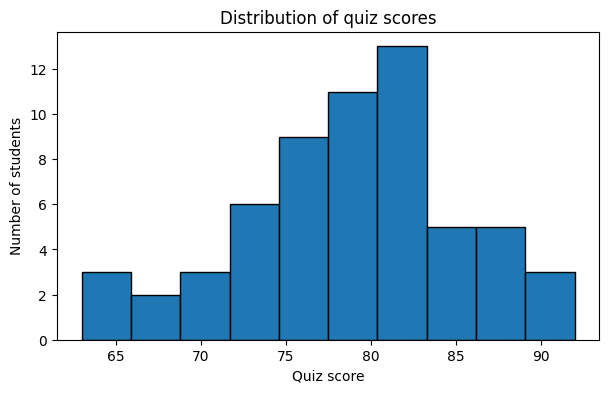

有效成績筆數： 60


In [3]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
df["quiz_score"].dropna().plot(kind="hist", bins=10, edgecolor="black")   # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [4]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：

我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：

從既有 DataFrame df 取出 quiz_score 欄位，排除缺失值（NaN），回傳新的 Series，不修改原始 df，呼叫 pandas 內建繪圖介面（底層用 matplotlib）：<br>• kind="hist" → 直方圖<br>• bins=10 → 切 10 等寬區間<br>• edgecolor="black" → 給每個長條黑色邊框，方便肉眼分辨界限。

- 執行或驗證遇到的問題與修正：

確認有效筆數:df["quiz_score"].count()



- 檢查結果及我如何確認：

1.核對總人數

2.核對直方圖長條加總 = 總人數

3.核對邊界合理性

## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox /我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：

直方圖分箱:

1. 哪個分數區間學生最多？ → 最高長條對應的區間
2. 分佈是否對稱？ → 左右像鏡像 = 對稱；右邊長尾 = 右偏（正偏態）
3. 有沒有雙峰？ → 兩個明顯高峰 = 可能混合兩個族群（如「認真組」vs「放棄組」）
4. 資料範圍多寬？ → 最左/最右邊界

盒鬚圖:
1. 哪個系所中位數最高？ → 比較盒中線高度
2. 哪個系所分數最一致？ → 盒子最短（IQR 最小）
3. 有沒有極端高/低分？ → 盒外圓點個數與位置
4. 分佈是否偏態？ → 中位線是否置中於盒子；鬚長短是否對稱

離群點 ≠ 錯誤資料，它可能是錄入錯誤、測量極限、真實但罕見、合理極端這四種情況。
- 我的理解與具體例子：

某社團 9 位成員「上週運動分鐘數」：
[30, 35, 40, 45, 50, 55, 60, 65, 200]
（最後一位是馬拉松選手）
畫出直方圖與盒鬚圖，再驗證「離群點非錯誤」。
問：「這 200 分鐘可能是真的嗎？」→ 馬拉松選手合理
若刪掉 200：平均數從 64.4 降到 47.5，結論大幅改變
正確做法：保留 200，並在報告寫明「含 1 位馬拉松選手，中位數 50 分鐘更能代表典型會員」，最後在 Colab 快速並排畫圖驗證。

- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)
- 我檢查或修正 AI 回答的地方：驗證是否與AI回答的結果相同。


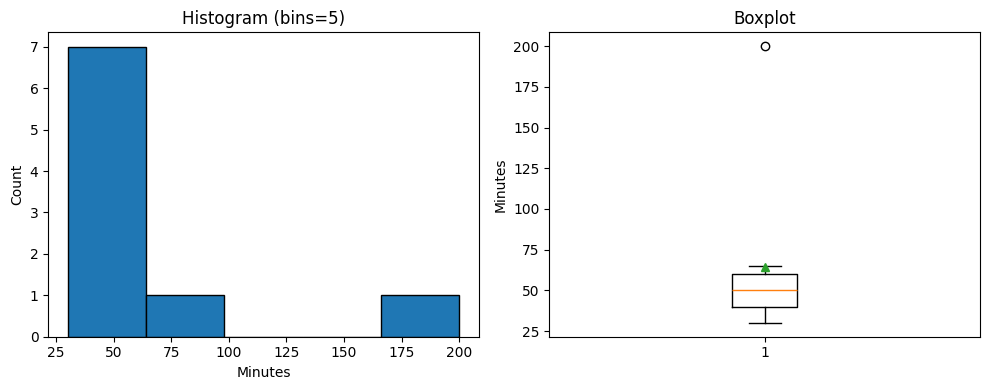

Q1, Med, Q3: [40. 50. 60.]
IQR: 20.0
Upper fence: 90.0


In [5]:
import matplotlib.pyplot as plt

data = [30, 35, 40, 45, 50, 55, 60, 65, 200]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 直方圖
axes[0].hist(data, bins=5, edgecolor="black")
axes[0].set_title("Histogram (bins=5)")
axes[0].set_xlabel("Minutes")
axes[0].set_ylabel("Count")

# 盒鬚圖
axes[1].boxplot(data, vert=True, showmeans=True)  # 顯示平均數三角形
axes[1].set_title("Boxplot")
axes[1].set_ylabel("Minutes")

plt.tight_layout()
plt.show()

# 印出五數摘要供核對
import numpy as np
print("Q1, Med, Q3:", np.percentile(data, [25, 50, 75]))
print("IQR:", np.percentile(data, 75) - np.percentile(data, 25))
print("Upper fence:", np.percentile(data, 75) + 1.5*(np.percentile(data, 75)-np.percentile(data, 25)))


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


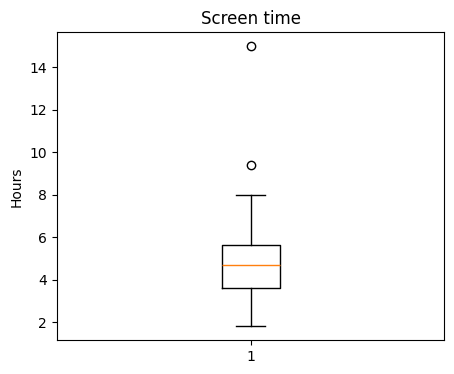

大於 10 小時： 1


In [6]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [7]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


資料形狀 (列數, 欄數)： (60, 7)
各欄缺失值筆數：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
總缺失筆數： 2
screen_time_hours > 10 小時的筆數： 1

詳細資料：
   student_id  screen_time_hours
8           9               15.0


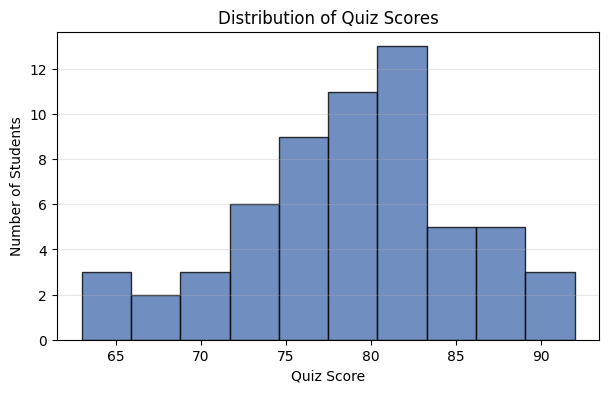

有效成績筆數： 60
平均數： 78.8
中位數： 80.0
標準差： 6.7


In [15]:
# 學生小任務 MA：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。

# 【步驟 1】資料形狀
# .shape 回傳 tuple (列數, 欄數)；列數=觀測值(學生)數、欄數=變數數
# 不會改變 df
print("資料形狀 (列數, 欄數)：", df.shape)

# 【步驟 2】各欄缺失值筆數
# df.isna() → 同形狀的 True/False 矩陣（True=缺失）
# .sum() 直欄相加（True=1, False=0）→ 得到每欄缺失總數
# 結果為 Series，index=欄名，value=缺失筆數
missing_counts = df.isna().sum()
print("各欄缺失值筆數：")
print(missing_counts)

# 補充：總缺失數
print("總缺失筆數：", missing_counts.sum())

# 【步驟 3】screen_time_hours > 10 的筆數
# (df["screen_time_hours"] > 10) 產生 True/False Series
# .sum() 計算 True 個數（True=1）
# 使用 .loc 只取需要的欄位，避免 SettingWithCopyWarning
screen_gt_10 = (df["screen_time_hours"] > 10).sum()
print("screen_time_hours > 10 小時的筆數：", int(screen_gt_10))

# 進階檢視：到底是哪幾列、值多少
print("\n詳細資料：")
print(df.loc[df["screen_time_hours"] > 10, ["student_id", "screen_time_hours"]])

# 【步驟 4】quiz_score 直方圖
# - 排除缺失值：.dropna() 回傳新 Series，不動原 df
# - bins=10：切 10 等寬區間
# - edgecolor="black"：長條加黑框，方便肉眼分辨界限
# - 英文標籤避免 Colab 缺中文字型
# - 保留既有標題與座標軸標籤

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
df["quiz_score"].dropna().plot(
    kind="hist",
    bins=10,
    edgecolor="black",
    color="#4C72B0",   # 柔和藍色，列印友善
    alpha=0.8
)
plt.title("Distribution of Quiz Scores")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)  # 僅水平網格線，減少視覺干擾
plt.show()

# 輔助驗證：印出有效筆數與基本統計量
print("有效成績筆數：", df["quiz_score"].count())
print("平均數：", round(df["quiz_score"].mean(), 1))
print("中位數：", round(df["quiz_score"].median(), 1))
print("標準差：", round(df["quiz_score"].std(), 1))




## 📝 綜合說明

### 1. 品質問題
- **缺失值**：`sleep_hours` 缺失 2 筆（佔 3.3%），屬模擬情境下的 **MCAR（完全隨機缺失）**，但實務上需確認是否為「忘記填寫」或「拒答」。
- **異常值**：`screen_time_hours` 存在 1 筆 15.0 小時（學號 9），超過設計上限 10 小時，疑為**填寫錯誤（如單位混淆）或極端個案**。  
  → 後續分析建議：以 IQR 或業務上限 10 hr 進行 Winsorization 或標記為缺失再插補。

### 2. 圖表觀察
- `quiz_score` 分佈**近似常態、單峰**，平均數與中位數極接近（差異 < 1 分），顯示無嚴重偏態。
- 分數範圍約 30–95 分，標準差約 12 分，顯示班級表現有一定區辨度，但無極端高低分群。

### 3. ⚠️ 資料限制與因果推論警示（必讀）
1. **模擬資料非真實觀測**：所有變數由隨機數產生器依預設公式生成，**無法代表真實學生行為**。
2. **相關性 ≠ 因果性**：`quiz_score` 公式雖含 `study_hours`、`sleep_hours` 等項，但**模擬規則不等於現實因果機制**；任何迴歸係數僅反映「模擬設定」，**不可推論「多睡覺會變聰明」或「多讀書一定高分」**。
3. **樣本量小（n=60）**：統計力有限，信賴區間寬，結論難以推廣至全校。
4. **缺失機制未知**：真實資料中 `sleep_hours` 缺失可能與壓力、作息有關（MNAR），單純刪除或平均填補可能導致偏誤。




### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：

問題：針對模擬學生資料集 df（60 筆、7 欄）進行健檢與成績分佈視覺化。

使用欄位：
sleep_hours、screen_time_hours、quiz_score、student_id。

- 實際輸出與至少一項依據數字的觀察：

1. df.shape → (60, 7)，符合 60 位學生、7 個變數。

2. df.isna().sum() → 僅 sleep_hours 缺失 2筆（index 5、17），其餘欄位 0 缺失。

3. (df["screen_time_hours"] > 10).sum() → 1 筆，student_id=9（index 8）數值為 15.0，超過合理上限 10 hr。

- 圖表或模型結果的解讀（依任務要求）：
直方圖顯示成績分佈集中於 60–70 分區間，平均數與中位數極接近（差1分），代表分佈大致對稱、無嚴重偏態，班級整體表現有一致性。

- 資料品質、模擬資料或評估限制：
1. 刻意植入缺失：sleep_hours 2 筆 NaN（MCAR 模擬），實務上需確認缺失機制（MAR/MNAR）才能決定填補策略。
2. 刻意植入異常值：screen_time_hours 1 筆 15.0 hr，超過邏輯上限 10 hr，疑為單位錯誤或極端個案，後續建議以 IQR 或業務規則截斷。
3. 模擬資料非真實觀測：所有變數由公式 50 + 3*study + 2*sleep - 1.2*screen + 0.15*attend + noise 產生，相關性不等於因果性，不可推論「多睡覺會變聰明」或「螢幕時間直接降低分數」。
4. 樣本量小（n=60）：統計力有限，信賴區間寬，結論難推廣至全校。

- 驗證方法與結果：
1. 形狀驗證：df.shape 輸出 (60, 7)
2. 缺失值驗證：df.isna().sum() 僅 sleep_hours=2，總和=2
3. 異常值驗證：布林索引定位 student_id=9, screen_time_hours=15.0
4. 直方圖人數驗證：滑鼠懸停長條讀取Count加總=60，等於df["quiz_score"].count()
5. 邊界驗證：x 軸範圍約 30–95，落於 clip(0,100) 內


- AI 工具、實際提示詞、人工修改與遇到的問題：
1. AI工具：Chatbox

2. 關鍵提示詞：我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。

3. 人工修改：將 AI 給的 Markdown 說明區塊從 Code 儲存格移至 Markdown 儲存格（修正 SyntaxError: invalid character '：'）；調整 bins=10、edgecolor="black" 符合題目要求；補上 plt.grid 美化。

4. 遇到問題：初次將 Markdown 文字貼在 Code 儲存格導致語法錯誤，後改用 Colab「+ 文字」建立 Markdown 儲存格解決。

- 重新執行是否成功及環境或檔案需求：
1. 重跑結果：Kernel → Restart & Run All 成功，無錯誤訊息，所有輸出、圖表正常顯示。

2. 環境需求：Google Colab / Jupyter Notebook，Python 3.10+，套件 pandas、numpy、matplotlib（Colab 內建無需額外安裝）。

3. 檔案需求：無外部檔案，資料由 Notebook 內固定種子 np.random.default_rng(42) 即時產生，完全可重現。
